# SAM 2 for Roman Space Telescope: Tutorial 05
## Training Boundary-Aware UNet++ for Ultra-Fast Astronomical Segmentation

This tutorial demonstrates how to train and run a **UNet++ (Nested U-Net)** convolutional network on Roman Space Telescope imaging with **3-class boundary-aware supervision**:
- **Class 0**: Sky Background
- **Class 1**: Source Interior / Core
- **Class 2**: Source Perimeter & Inter-Object Touching Boundaries

### Key Advantages of UNet++ over SAM 2:
1. **$5\times - 10\times$ Faster Inference**: Single forward pass across the image ($<15$ ms per $512 \times 512$ crop).
2. **Prompt-Free**: Segments the entire image automatically without requiring point clicks, boxes, or grid queries.
3. **Physical Deblending**: The network explicitly predicts separation boundaries between touching galaxies, allowing marker-controlled watershed to cleanly split overlapping sources into distinct instances.
4. **Automatic Hardware Optimization**: Runs on **Apple Silicon MPS** in full FP32 and auto-scales on **NVIDIA CUDA GPUs (A100 / L4 / T4)** with TF32 Tensor Cores, `bfloat16` AMP, and pinned memory.

### Google Colab Setup (Optional)
If running in Google Colab, uncomment and run the setup cell below:

In [ ]:
# In Google Colab, uncomment and run:
# !nvidia-smi
# !git clone https://github.com/PabloMSanAla/sam2roman.git
# %cd sam2roman
# !pip install -e .
#
# If your Roman data is on Google Drive:
# from google.colab import drive
# drive.mount('/content/drive')

### Step 1: Detect Hardware & Configure Device Optimization

In [1]:
import os
import sys
from pathlib import Path

for p in ['/content/sam2roman/src', 'src', '../src', '../../src']:
    resolved = Path(p).resolve()
    if resolved.exists() and str(resolved) not in sys.path:
        sys.path.insert(0, str(resolved))
        break

import matplotlib.pyplot as plt
import numpy as np
import torch

from sam2roman.training.dataset import AstronomicalDataset
from sam2roman.training.unetpp_trainer import UNetPPTrainer
from sam2roman.inference.unetpp_segmentor import UNetPPSegmentor
from sam2roman.visualization.display import plot_detection_summary, plot_masks_overlay

# Device auto-detection
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    device = "cuda"
    batch_size = 16 if vram_gb >= 30.0 else 8
    num_workers = min(4, os.cpu_count() or 4)
    print(f"[Hardware] Accelerator: {gpu_name} ({vram_gb:.1f} GB VRAM)")
    print(f"  -> Auto-configured: TF32=True, AMP (bfloat16), pin_memory=True, batch_size={batch_size}")
elif torch.backends.mps.is_available():
    device = "mps"
    batch_size = 4
    num_workers = 0
    print(f"[Hardware] Accelerator: Apple Silicon MPS (Metal Performance Shaders active)")
else:
    device = "cpu"
    batch_size = 2
    num_workers = 0
    print(f"[Hardware] Accelerator: CPU")

W1029 09:46:35.441000 22848 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


[Hardware] Accelerator: Apple Silicon MPS (Metal Performance Shaders active)


### Step 2: Create Astronomical Dataset with 3-Class Boundary Targets

Using `target_mode='dense_3class'`, `AstronomicalDataset` automatically creates 3-class target masks where touching and overlapping galaxies are separated by a 1-pixel boundary ridge.

In [6]:
images_dir = Path("/Volumes/T7/storage/ROMAN/synthetic_romanisim_sam2/images")
masks_dir  = Path("/Volumes/T7/storage/ROMAN/synthetic_romanisim_sam2/masks")

if not images_dir.exists() or not masks_dir.exists():
    print("Warning: External paths not found. Using local sample_data fallback.")
    images_dir = Path("sample_data")
    masks_dir  = Path("sample_data")

dataset = AstronomicalDataset.from_directories(
    images_dir=images_dir,
    masks_dir=masks_dir,
    pattern="*.fits",
    crop_size=512,
    target_mode="dense_3class",  # 3-class boundary target: 0=bg, 1=interior, 2=edge
    stretch_type="leakysb",      # Default surface brightness stretch
    max_samples=4,               # Number of exposures for demo run
)
print(f"Created {len(dataset)} training cutouts with boundary-aware targets!")

# Train / Validation Split (80% / 20%)
n_train = max(1, int(0.8 * len(dataset)))
n_val = len(dataset) - n_train
train_ds, val_ds = torch.utils.data.random_split(
    dataset, [n_train, n_val], generator=torch.Generator().manual_seed(42)
)
print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)}")

Created 620 training cutouts with boundary-aware targets!
Train samples: 496 | Val samples: 124


### Step 3: Inspect a Sample 3-Class Target (Background, Interior, Edge)

AttributeError: module 'matplotlib.cm' has no attribute 'get_cmap'

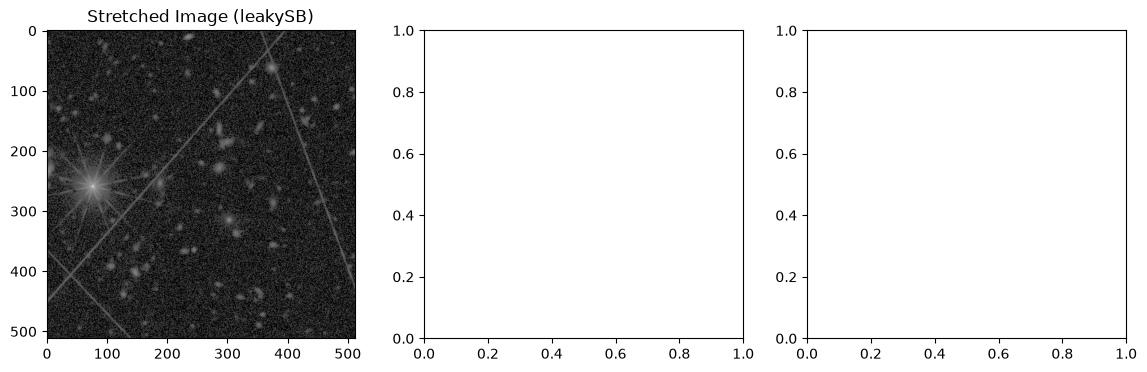

In [4]:
sample = train_ds[0]
raw_img = sample["raw_data"]
target = sample["target"].numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(sample["pil_image"])
axes[0].set_title("Stretched Image (leakySB)")

# Color map for 3 classes: 0=black, 1=cyan (interior), 2=red (boundary)
cmap = plt.get_cmap("viridis", 3)
im1 = axes[1].imshow(target, cmap=cmap, vmin=0, vmax=2)
axes[1].set_title("3-Class Ground Truth Target (0=bg, 1=int, 2=edge)")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# Edge-only visualization
axes[2].imshow(target == 2, cmap="hot")
axes[2].set_title("Boundary & Inter-Object Edges")

plt.tight_layout()
plt.show()

### Step 4: Configure `UNetPPTrainer` & Execute Training Loop

In [ ]:
output_dir = Path("checkpoints")
output_dir.mkdir(parents=True, exist_ok=True)

trainer = UNetPPTrainer(
    in_channels=3,
    num_classes=3,
    features=(32, 64, 128, 256, 512),
    learning_rate=3e-4,
    class_weights=(1.0, 2.5, 4.0),  # Prioritize thin edges and interiors
    device=device,
)

epochs = 50
history = trainer.train(
    dataset=train_ds,
    val_dataset=val_ds,
    epochs=epochs,
    batch_size=batch_size+2,
    num_workers=num_workers,
    output_dir=output_dir,
    verbose=True,
)

[sam2roman] Starting UNet++ training for 50 epochs on mps...
  -> Model Architecture:  UNet++ (Nested U-Net, 3 classes: bg, interior, boundary)
  -> Trainable weights:   9,159,747 parameters
  -> Training cutouts:    496
  -> Validation cutouts:  124
  -> Batch size:          4
  -> DataLoader:          shuffle=True, num_workers=0, pin_memory=False
  -> Apple Silicon MPS:   Metal Performance Shaders active (FP32)
---------------------------------------------------------------------------


KeyboardInterrupt: 

### Step 5: Plot Convergence & IoU Metrics

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ep_range = range(1, epochs + 1)

ax1.plot(ep_range, history["train_loss"], 'o-', label="Train Loss", color="royalblue")
if history["val_loss"]:
    ax1.plot(ep_range, history["val_loss"], 's--', label="Val Loss", color="crimson")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss (CE + Dice)")
ax1.set_title("UNet++ Loss Convergence")
ax1.grid(True, alpha=0.3)
ax1.legend()

if history["val_macro_iou"]:
    ax2.plot(ep_range, history["val_macro_iou"], '^-', label="Macro IoU", color="purple")
    ax2.plot(ep_range, history["val_interior_iou"], 'o--', label="Interior IoU", color="forestgreen")
    ax2.plot(ep_range, history["val_boundary_iou"], 'd--', label="Edge IoU", color="orange")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("IoU")
    ax2.set_title("Validation Metrics")
    ax2.grid(True, alpha=0.3)
    ax2.legend()

plt.tight_layout()
plt.show()

### Step 6: Test Inference & Watershed Deblending

We run `UNetPPSegmentor.segment_image()` on an astronomical field. In a single forward pass ($<15$ ms), the model outputs the 3-class probability map, detects interior core seeds, and applies marker-controlled watershed to separate blended sources into discrete instances.

In [ ]:
best_ckpt = output_dir / "unetpp_best.pt"
if not best_ckpt.exists():
    best_ckpt = output_dir / f"unetpp_epoch_{epochs}.pt"

segmentor = UNetPPSegmentor.from_checkpoint(best_ckpt, device=device)

val_sample = val_ds[0]
test_raw = val_sample["raw_data"]

results = segmentor.segment_image(
    image=test_raw,
    stretch_type="leakysb",
    interior_thresh=0.45,
    min_area=10,
    verbose=True,
)
print(f"\nDetected {len(results)} discrete deblended astronomical sources!")

# Measure source photometry
catalog = results.compute_photometry(test_raw, verbose=True)
if catalog:
    brightest = max(catalog, key=lambda s: s["net_flux"])
    print(f"Brightest source: ID #{brightest['source_id']} with Net Flux = {brightest['net_flux']:.1f} (SNR: {brightest['snr']:.1f})")

# 3-Panel detection summary
fig_summary = plot_detection_summary(
    image=test_raw,
    seg_result=results,
    title_prefix="UNet++ Deblended Cutout",
)
plt.show()